# Section Condition × Rerank Alpha Sweep Analysis

**Rerun basis (2026-09-06, fresh round):** the production API must serve the articles-only collection `DS_INCLUDE_2026_09_02_DEEPINFRA_2048` (65,677 vectors, 1,594 documents; corpus reselected from the 2026-09-02 snapshot with >=4 sections AND article-only criteria; 75 non-article papers purged 2026-09-06). The config cell verifies all three values via `/health` and stops on any mismatch. Note the purge does not change what any condition can retrieve (the pipeline always applied the `pub_type == "article"` filter), so differences from earlier runs reflect the corpus reselection and generation variability. All earlier outputs are archived in `analysis/output/_archive_pre_fresh_run_2026-09-06/`.

Evaluates how the **set of indexed sections** and the **reranking alpha parameter** jointly affect answer quality.
Runs the T21 RAG pipeline in a 2D sweep: 3 section conditions × 6 alpha values, with LLM-as-judge disabled for speed.

**Scientific Reports revision (v1):** re-run on the expanded 30-question positive-control benchmark
(up from n=12), per reviewer feedback that the original benchmark size was too small. Output kept
separate from the original submission's `output/section_condition/` results.

**Rerank alpha (α):** blends vector similarity and cross-encoder reranking score:
`combined = α × vector_score_norm + (1 − α) × cross_encoder_score_scaled`
(0.0 = pure cross-encoder; 1.0 = pure vector similarity)

| Condition | Sections | Rationale |
|-----------|----------|-----------|
| **C1** | Abstract, Introduction | Background / context only |
| **C2** | Abstract, Introduction, Results, Discussion, Methods, Conclusion | Full corpus (all 6 sections) |
| **C3** | Results, Discussion, Methods, Conclusion | Evidence-only (current production default) |

**Alpha values swept:** `[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]`  
**LLM-as-judge:** disabled (`enable_judge=False`) for all sweep calls (speed).

**Metrics:** BERTScore Precision / Recall / F (sentence-level cosine via `nvidia/llama-nemotron-embed-vl-1b-v2`, 2048-dim) + semantic similarity (document-level cosine). Embeddings computed via the production `/embed_batch` API endpoint — the same DeepInfra model used to index the corpus.

> **Key finding (n=30 re-run, 2026-09-03 pre-purge collection - to be refreshed by the rerun below):** the optimal rerank alpha for the production `C3: Evidence-only` condition
> shifted from the previously-configured **α=0.2 to α=0.8** on both metrics — BERTScore F 0.574 vs. 0.556
> at α=0.2 (+0.019), Semantic Similarity 0.649 vs. 0.629 (+0.021). The same higher-α preference (0.6–0.8)
> holds across C1 and C2 as well, suggesting this reflects the current DeepInfra embed+rerank stack rather
> than noise specific to one condition. See Cell 6/7 for the full pivot tables and heatmap.

**Output:** `analysis/output/ScientificReportRevisionV1/section_condition/`

| File | Description |
|------|-------------|
| `responses_section_alpha_sweep.csv` | Raw summaries — one row per (condition, alpha, question) |
| `bertscores_section_alpha_sweep.csv` | BERTScore P/R/F + SemanticSim per row |
| `section_alpha_heatmap.pdf/.jpg` | Heatmap: condition × alpha, BERTScore F & SemanticSim |
| `section_alpha_barchart_*.pdf/.jpg` | Grouped bar chart: BERTScore F1 & SemanticSim vs alpha, one bar group per condition |

## Cell 1 — Configuration

Sets all runtime parameters for the 2D sweep.

| Parameter | Value | Description |
|-----------|-------|-------------|
| `BACKEND_URL` | `http://127.0.0.1:8698` | T21 RAG FastAPI endpoint |
| `TOP_K` | `20` | Retrieval candidates per query |
| `ALPHA_VALUES` | `[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]` | Rerank blend values to sweep |
| `ENABLE_JUDGE` | `False` | LLM-as-judge disabled for all sweep calls |
| `SAVE_DPI` | `300` | Output figure resolution |

**Section conditions:**

| Label | Sections retrieved | Notes |
|-------|--------------------|-------|
| `C1` | Abstract, Introduction | Background / context only — no primary evidence |
| `C2` | Abstract, Introduction, Results, Discussion, Methods, Conclusion | Full 6-section corpus |
| `C3` | Results, Discussion, Methods, Conclusion | Evidence-only — current production default |

**Embedding model (BERTScore):** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via the production `/embed_batch` API endpoint — the same model used to index the corpus, ensuring retrieval and evaluation are in the same embedding space.

**Questions:** `Revised_DownSyndrome_60_Questions_Final_linked.xlsx` (Scientific Reports revision — 30 positive-control + 30 negative-control questions; only positive controls with a ground-truth answer are used here, see Cell 3).

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv

_NB_DIR  = Path('..').resolve()          # analysis/
_SRV_DIR = _NB_DIR.parent / 'srv'
load_dotenv(_NB_DIR / '.env')

# Scientific Reports revision (v1) — 60-question benchmark, output kept separate
# from the original submission's output/section_condition/ results.
OUTPUT_DIR = _NB_DIR / 'output' / 'ScientificReportRevisionV1' / 'section_condition'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BACKEND_URL = os.getenv('BACKEND_URL', 'http://127.0.0.1:8698')

# ── Live collection check (three-way: name + vectors + documents) ─────────────
import requests as _rq
EXPECTED_COLLECTION = 'DS_INCLUDE_2026_09_02_DEEPINFRA_2048'   # articles-only, stored==searchable since 2026-09-06 purge
EXPECTED_VECTORS    = 65_677
EXPECTED_DOCS       = 1_594
API_VERIFIED = False   # generation/scoring cells refuse to run unless this is True
try:
    _h = _rq.get(f'{BACKEND_URL}/health', timeout=30).json()
    _hc = _h['config']['milvus_collection']
    _hv = int(str(_h['database']['total_vectors']).replace(',', ''))
    _hd = int(str(_h['database']['estimated_documents']).replace(',', ''))
    assert _hc == EXPECTED_COLLECTION, (
        f'API serves {_hc!r}, expected {EXPECTED_COLLECTION!r} - fix srv/.env and recreate the api '
        'container (docker compose up -d api), or update EXPECTED_COLLECTION here if intentional.')
    assert _hv == EXPECTED_VECTORS, f'API vectors {_hv:,} != expected {EXPECTED_VECTORS:,}'
    assert _hd == EXPECTED_DOCS,    f'API documents {_hd:,} != expected {EXPECTED_DOCS:,}'
    API_VERIFIED = True
    print(f'Collection   : {_hc} (verified: {_hv:,} vectors, {_hd:,} documents)')
except Exception as _e:
    print(f'[WARN] Backend NOT verified: {_e}')
    print('[WARN] Plot cells (6-8) still work from results saved on disk;')
    print('[WARN] the generation (Cell 4) and scoring (Cell 5) cells will refuse to run.')
# Embeddings for BERTScore use the production /embed_batch endpoint
# → DeepInfra nvidia/llama-nemotron-embed-vl-1b-v2 (2048-dim), same model as the RAG pipeline

QUESTIONS_XLSX = (
    _NB_DIR / 'input'
    / 'Revised_DownSyndrome_60_Questions_Final_linked.xlsx'
)

TOP_K    = 20
SAVE_DPI = 300

# ── Section conditions ────────────────────────────────────────────────────────
CONDITIONS = {
    'C1: Abstract + Introduction': [
        'Abstract', 'Introduction',
    ],
    'C2: Full Corpus (all 6 sections)': [
        'Abstract', 'Introduction', 'Results', 'Discussion', 'Methods', 'Conclusion',
    ],
    'C3: Evidence-only (Results + Discussion + Methods + Conclusion)': [
        'Results', 'Discussion', 'Methods', 'Conclusion',
    ],
}

# ── Rerank alpha sweep ────────────────────────────────────────────────────────
# combined = alpha * vector_score_norm + (1 - alpha) * cross_encoder_score_scaled
# 0.0 = pure cross-encoder reranking; 1.0 = pure vector similarity
ALPHA_VALUES = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Disable LLM-as-judge for all sweep calls (speed; per-request override in main.py)
ENABLE_JUDGE = False

print(f'API URL      : {BACKEND_URL}')
print(f'Questions    : {QUESTIONS_XLSX.name}  (exists={QUESTIONS_XLSX.exists()})')
print(f'Output       : {OUTPUT_DIR}')
print(f'Alpha values : {ALPHA_VALUES}')
print(f'Enable Judge : {ENABLE_JUDGE}')
print()
for cname, secs in CONDITIONS.items():
    print(f'  {cname}')
    print(f'    → {secs}')

Collection   : DS_INCLUDE_2026_09_02_DEEPINFRA_2048 (verified: 65,677 vectors, 1,594 documents)
API URL      : http://127.0.0.1:8698
Questions    : Revised_DownSyndrome_60_Questions_Final_linked.xlsx  (exists=True)
Output       : /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition
Alpha values : [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
Enable Judge : False

  C1: Abstract + Introduction
    → ['Abstract', 'Introduction']
  C2: Full Corpus (all 6 sections)
    → ['Abstract', 'Introduction', 'Results', 'Discussion', 'Methods', 'Conclusion']
  C3: Evidence-only (Results + Discussion + Methods + Conclusion)
    → ['Results', 'Discussion', 'Methods', 'Conclusion']


## Cell 2 — Imports

Loads all required libraries and configures global Matplotlib style settings.

| Library | Purpose |
|---------|---------|
| `requests` | HTTP calls to the T21 RAG API (`/answer`, `/embed_batch`) |
| `numpy` | Cosine similarity matrix computation for BERTScore |
| `pandas` | DataFrames for responses, scores, and pivot tables |
| `matplotlib` / `seaborn` | Heatmaps and line charts |
| `tqdm` | Progress bars for the sweep loop |

No OpenAI client is imported — all embeddings go through the production `/embed_batch` endpoint.

In [2]:
import re
import time
from typing import List

import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

mpl.rcParams.update({
    'font.family'       : 'sans-serif',
    'font.size'         : 13,
    'axes.titlesize'    : 15,
    'axes.titleweight'  : 'bold',
    'axes.labelsize'    : 17,
    'axes.labelweight'  : 'bold',
    'axes.linewidth'    : 1.8,
    'xtick.major.width' : 1.8,
    'ytick.major.width' : 1.8,
    'xtick.major.size'  : 5.0,
    'ytick.major.size'  : 5.0,
    'xtick.labelsize'   : 14,
    'ytick.labelsize'   : 14,
    'legend.fontsize'   : 10,
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'figure.facecolor'  : 'white',
    'axes.facecolor'    : 'white',
    'pdf.fonttype'      : 42,
    'ps.fonttype'       : 42,
})
print('Imports OK')

Imports OK


/home/user/anaconda3/envs/dschat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Cell 3 — Load Questions & Ground Truth

Reads the benchmark question set from the evaluation Excel file and filters to **positive-control questions** that have a ground-truth answer.

**Source file:** `Revised_DownSyndrome_60_Questions_Final_linked.xlsx` (Scientific Reports revision — 60 total questions, 30 positive + 30 negative controls)  
**Sheet:** `Questions_for_testing`

**Columns used:**

| Column | Description |
|--------|-------------|
| `Original question` | The research question sent to the RAG pipeline |
| `Answer` | Expert ground-truth answer used as BERTScore reference |
| `CTRL_Type` | `Positive` (answerable) or `Negative` (unanswerable) — matched case-insensitively |

Only rows with `CTRL_Type == 'positive'` (case-insensitive) and a non-empty `Answer` are included — **30 questions** in the revised set. Negative controls (intentionally unanswerable questions) are excluded because they have no valid ground-truth reference for scoring.

In [3]:
df_q = pd.read_excel(QUESTIONS_XLSX, sheet_name='Questions_for_testing')
df_q.columns = df_q.columns.str.strip()

# Keep positive controls with a ground-truth answer
df_pos = df_q[
    (df_q['CTRL_Type'].str.lower() == 'positive') &
    df_q['Answer'].notna() &
    (df_q['Answer'].str.strip() != '')
].reset_index(drop=True)

questions  = df_pos['Original question'].tolist()
gt_answers = df_pos['Answer'].tolist()

print(f'Positive-control questions with GT: {len(questions)}')
for i, q in enumerate(questions):
    print(f'  Q{i+1:02d}: {q[:90]}')

Positive-control questions with GT: 30
  Q01: Which clinical conditions are people with Down syndrome at higher risk for?
  Q02: Which clinical conditions are people with Down syndrome at lower risk for?
  Q03: Why do people with Down syndrome tend to have hyperactive immune systems?
  Q04: Why are people with Down syndrome at high risk of developing Alzheimer's disease?
  Q05: Do individuals with Down syndrome have overactive thyroid glands?
  Q06: Which interferon receptors are triplicated in Down syndrome?
  Q07: How is Stat1 signaling affected in Down syndrome?
  Q08: Which circulating immune cell is consistently depleted in T21 throughout the lifespan?
  Q09: What are some advantages and caveats of the Ts65Dn and Dp16 mouse models of Down syndrome?
  Q10: Are individuals with Down syndrome more prone to high blood pressure?
  Q11: What neurodegeneration is associated with Down syndrome?
  Q12: What type of cancer are individuals with Down Syndrome less prone to developing?
  Q13: 

## Cell 4 — Generate Responses: 2D Sweep (Conditions × Alpha)

Calls `POST /answer` for every combination of section condition and rerank alpha value.

**Per-request parameters:**

| Parameter | Value | Notes |
|-----------|-------|-------|
| `sections` | condition-specific list | Restricts Milvus retrieval to these sections only |
| `rerank_alpha` | swept 0.0 → 1.0 | Overrides `RERANK_ALPHA` from `.env` for this request |
| `enable_judge` | `False` | Skips the `judge_improve` LangGraph node (saves ~15–30 s per call) |
| `top_k` | `20` | Retrieval candidates before reranking |
| `timeout` | 180 s | Per-request HTTP timeout |

**Total API calls:** 3 conditions × 6 alpha values × N questions  
(3 × 6 × 30 = **540 calls** for the revised 30-question positive-control set; completed in ~2.5 h at ~14–23 s/call)

**`_extract_summary`:** strips `[PMCxxxxxxx:Section](url)` citation links from the returned markdown before scoring, so BERTScore operates on clean prose text.

**`_call_api`:** returns an empty string on any HTTP or timeout error; the scoring step handles empty strings gracefully (returns 0.0).

**Checkpointing (resume-safe):** every successful response is appended to
`checkpoint_responses.jsonl` and flushed to disk immediately. If the kernel dies
mid-sweep, rerun this cell: already-collected (condition, alpha, question) keys are
skipped and the sweep continues from where it stopped. Responses where the API
errored are NOT saved (never considered); rerunning this cell retries them.


In [4]:
def _extract_summary(markdown: str) -> str:
    """Extract the # Summary body; strip inline PMC citation tags."""
    m = re.search(r'(?im)^#\s+Summary\s*\n(.*?)(?=^#\s+|\Z)', markdown, re.S)
    body = m.group(1).strip() if m else markdown.strip()
    body = re.sub(r'\[PMC[^\]]+\](?:\([^)]*\))?', '', body)
    return body.strip()


def _call_api(question: str, sections: List[str], alpha: float,
              top_k: int = TOP_K, enable_judge: bool = False):
    """POST /answer with explicit section list, rerank_alpha, and enable_judge flag.
    Returns the extracted Summary text, or None on ANY API error - error responses
    are never considered/checkpointed; they are retried on the next run of this cell."""
    try:
        r = requests.post(
            f'{BACKEND_URL}/answer',
            json={
                'question'    : question,
                'top_k'       : top_k,
                'sections'    : sections,
                'rerank_alpha': alpha,
                'enable_judge': enable_judge,
            },
            timeout=180,
        )
        r.raise_for_status()
        md = r.json().get('markdown', '')
        return _extract_summary(md)
    except Exception as e:
        print(f'    [API_ERROR] {e}')
        return None


# ── Resume-safe 2D sweep: conditions x alpha, checkpointed to disk ───────────
# Every successful response is appended to checkpoint_responses.jsonl and
# flushed immediately. If the kernel dies, just rerun this cell: already-
# collected (condition, alpha, question) keys are skipped and the sweep
# continues from where it stopped. API-error responses are NOT checkpointed.
import json as _json

CKPT_RESPONSES = OUTPUT_DIR / 'checkpoint_responses.jsonl'


def _resp_key(cname, alpha, q_idx):
    return (cname, round(float(alpha), 2), int(q_idx))


def _load_response_checkpoint():
    done = {}
    if CKPT_RESPONSES.exists():
        with open(CKPT_RESPONSES) as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                try:
                    rec = _json.loads(line)
                except _json.JSONDecodeError:
                    continue   # partial last line from a crash - will be redone
                done[_resp_key(rec['condition'], rec['alpha'], rec['q_idx'])] = rec['summary']
    return done


assert API_VERIFIED, 'Backend not verified against the expected collection (see Cell 1) - refusing to generate.'

done_map    = _load_response_checkpoint()
total_calls = len(CONDITIONS) * len(ALPHA_VALUES) * len(questions)
print(f'Checkpoint: {len(done_map)}/{total_calls} responses already on disk ({CKPT_RESPONSES.name})')

n_new = n_err = 0
with open(CKPT_RESPONSES, 'a') as fh:
    for cname, sections in CONDITIONS.items():
        for alpha in ALPHA_VALUES:
            tag = f'{cname.split(":")[0]}  a={alpha}'
            pending = [(i, q) for i, q in enumerate(questions)
                       if _resp_key(cname, alpha, i + 1) not in done_map]
            if not pending:
                print(f'── {tag} ── all {len(questions)} done, skipping')
                continue
            print(f'\n── {tag} ── {len(pending)} pending')
            for i, q in tqdm(pending, desc=f'{tag[:40]}'):
                summary = _call_api(q, sections, alpha, enable_judge=ENABLE_JUDGE)
                if summary is None or not summary.strip():
                    n_err += 1        # API error / empty -> not saved, retried next run
                    continue
                rec = {'condition': cname, 'alpha': alpha, 'q_idx': i + 1,
                       'question': q, 'ground_truth': gt_answers[i], 'summary': summary}
                fh.write(_json.dumps(rec) + '\n')
                fh.flush()
                done_map[_resp_key(cname, alpha, i + 1)] = summary
                n_new += 1
                time.sleep(0.3)

print(f'\nDone. new={n_new}  errors={n_err}  on_disk={len(done_map)}/{total_calls}')
if n_err or len(done_map) < total_calls:
    print(f'[WARN] {total_calls - len(done_map)} responses still missing - RERUN THIS CELL to retry them.')
else:
    print('All responses collected.')


Checkpoint: 540/540 responses already on disk (checkpoint_responses.jsonl)
── C1  a=0.0 ── all 30 done, skipping
── C1  a=0.2 ── all 30 done, skipping
── C1  a=0.4 ── all 30 done, skipping
── C1  a=0.6 ── all 30 done, skipping
── C1  a=0.8 ── all 30 done, skipping
── C1  a=1.0 ── all 30 done, skipping
── C2  a=0.0 ── all 30 done, skipping
── C2  a=0.2 ── all 30 done, skipping
── C2  a=0.4 ── all 30 done, skipping
── C2  a=0.6 ── all 30 done, skipping
── C2  a=0.8 ── all 30 done, skipping
── C2  a=1.0 ── all 30 done, skipping
── C3  a=0.0 ── all 30 done, skipping
── C3  a=0.2 ── all 30 done, skipping
── C3  a=0.4 ── all 30 done, skipping
── C3  a=0.6 ── all 30 done, skipping
── C3  a=0.8 ── all 30 done, skipping
── C3  a=1.0 ── all 30 done, skipping

Done. new=0  errors=0  on_disk=540/540
All responses collected.


## Cell 4b — Checkpoint: Save Raw Responses

Flattens the 3D result structure `results[condition][alpha][question_idx]` into a tidy DataFrame and saves to CSV immediately after generation — before any scoring step — so results are preserved even if scoring is interrupted.

**Output file:** `responses_section_alpha_sweep.csv`

**Schema:**

| Column | Description |
|--------|-------------|
| `q_idx` | 1-based question index |
| `question` | Full question text |
| `ground_truth` | Expert reference answer |
| `condition` | Section condition label (e.g. `C3: Evidence-only...`) |
| `alpha` | Rerank alpha value (0.0 – 1.0) |
| `summary` | Cleaned summary text returned by the RAG pipeline |

Also prints mean word counts per (condition, alpha) cell as a sanity check — unexpectedly short word counts indicate failed or evidence-gap responses.

**Disk-driven:** builds the final `responses_section_alpha_sweep.csv` from
`checkpoint_responses.jsonl` on disk (not from in-memory state), so it works
after a kernel restart. Warns about any (condition, alpha, question) keys still
missing (rerun Cell 4 to fill them).


In [5]:
# Consolidate the on-disk checkpoint into the final responses CSV.
# Reads ONLY from checkpoint_responses.jsonl (disk), never from in-memory state,
# so this works after a kernel restart.
done_map = _load_response_checkpoint()

rows, missing = [], []
for cname in CONDITIONS:
    for alpha in ALPHA_VALUES:
        for i, (q, gt) in enumerate(zip(questions, gt_answers)):
            key = _resp_key(cname, alpha, i + 1)
            if key not in done_map:
                missing.append(key)
                continue
            rows.append({
                'q_idx'       : i + 1,
                'question'    : q,
                'ground_truth': gt,
                'condition'   : cname,
                'alpha'       : alpha,
                'summary'     : done_map[key],
            })

if missing:
    print(f'[WARN] {len(missing)} responses missing (API errors / not yet run) - rerun Cell 4 first.')
    for k in missing[:10]:
        print(f'   missing: {k}')

df_resp  = pd.DataFrame(rows)
csv_path = OUTPUT_DIR / 'responses_section_alpha_sweep.csv'
df_resp.to_csv(csv_path, index=False)
print(f'Saved -> {csv_path}  ({len(df_resp)} rows)')

# Word-count sanity check
print('\nMean summary word counts (condition x alpha):')
for cname in CONDITIONS:
    c_short = cname.split(':')[0].strip()
    for alpha in ALPHA_VALUES:
        sub  = df_resp[(df_resp['condition'] == cname) & (df_resp['alpha'] == alpha)]
        wcs  = [len(t.split()) for t in sub['summary'] if t.strip()]
        mean = np.mean(wcs) if wcs else 0
        print(f'  {c_short}  a={alpha:.1f}  -> {mean:.0f} words  (n={len(wcs)})')


Saved -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/responses_section_alpha_sweep.csv  (540 rows)

Mean summary word counts (condition x alpha):
  C1  a=0.0  -> 99 words  (n=30)
  C1  a=0.2  -> 93 words  (n=30)
  C1  a=0.4  -> 104 words  (n=30)
  C1  a=0.6  -> 105 words  (n=30)
  C1  a=0.8  -> 98 words  (n=30)
  C1  a=1.0  -> 96 words  (n=30)
  C2  a=0.0  -> 103 words  (n=30)
  C2  a=0.2  -> 102 words  (n=30)
  C2  a=0.4  -> 105 words  (n=30)
  C2  a=0.6  -> 98 words  (n=30)
  C2  a=0.8  -> 98 words  (n=30)
  C2  a=1.0  -> 95 words  (n=30)
  C3  a=0.0  -> 96 words  (n=30)
  C3  a=0.2  -> 96 words  (n=30)
  C3  a=0.4  -> 98 words  (n=30)
  C3  a=0.6  -> 102 words  (n=30)
  C3  a=0.8  -> 98 words  (n=30)
  C3  a=1.0  -> 93 words  (n=30)


## Cell 5 — BERTScore & Semantic Similarity

Scores every (condition, alpha, question) row against its ground-truth answer using two complementary metrics.

**Embedding model:** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via `POST /embed_batch` on the production API — the same DeepInfra model used to embed the corpus. Using the same model for scoring as for retrieval ensures the similarity space is consistent.

---

### BERTScore (sentence-level)

Measures semantic overlap at the sentence level using cosine similarity between embedded sentences.

| Metric | Definition |
|--------|-----------|
| **Precision (P)** | For each candidate sentence, find the most similar reference sentence. Mean of these max-cosine values. High P = candidate doesn't hallucinate content absent from the reference. |
| **Recall (R)** | For each reference sentence, find the most similar candidate sentence. Mean of these max-cosine values. High R = candidate covers the key points in the reference. |
| **F-score (F)** | Harmonic mean of P and R. Primary ranking metric for this analysis. |

---

### Semantic Similarity (document-level)

Embeds the full candidate and reference as single vectors; returns their cosine similarity. Captures overall topical alignment rather than fine-grained sentence coverage.

---

**Output file:** `bertscores_section_alpha_sweep.csv` — one row per (condition, alpha, question) with columns `P`, `R`, `F`, `SS`.

**Checkpointing (resume-safe):** loads responses from `responses_section_alpha_sweep.csv`
on disk; each scored row is appended to `checkpoint_scores.jsonl` and flushed. On rerun,
already-scored rows are skipped. Rows whose /embed_batch call errored are NOT saved
(never considered); rerun this cell to retry them. The final consolidated scores are
written to `bertscores_section_alpha_sweep.csv`.


In [6]:
def _split_sentences(text: str) -> List[str]:
    parts = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in parts if len(s.strip()) > 10]


_ERR_MARKER_RE = re.compile(r'\[[A-Z][A-Z0-9_]*_ERROR\]|too many concurrent', re.I)

def _is_invalid_answer(text) -> bool:
    """True for answers that must NEVER be scored: empty strings and API-error
    marker responses (standing rule: excluded from scoring, never scored as 0)."""
    t = str(text or '').strip()
    return (not t) or t.lower() == 'nan' or bool(_ERR_MARKER_RE.search(t))


_EMBED_FAIL = {'row_failed': False, 'n': 0}   # tracks embed-API errors per scored row


def _embed_batch(texts: List[str], _dim: list = [0]) -> np.ndarray:
    """Embed texts via the production /embed_batch endpoint.
    Uses the active embedder (DeepInfra nvidia/llama-nemotron-embed-vl-1b-v2, 2048-dim).
    On failure returns zero vectors AND sets _EMBED_FAIL['row_failed'] so the caller
    can skip checkpointing that row (error responses are never scored/saved)."""
    try:
        r = requests.post(
            f'{BACKEND_URL}/embed_batch',
            json={'texts': texts},
            timeout=120,
        )
        r.raise_for_status()
        raw = r.text.strip()
        if not raw:
            print(f'    [EMBED_WARN] empty response body for {len(texts)} texts')
            _EMBED_FAIL['row_failed'] = True
            _EMBED_FAIL['n'] += 1
            fallback_dim = _dim[0] if _dim[0] else 2048
            return np.zeros((len(texts), fallback_dim), dtype=np.float32)
        data = r.json()
        arr = np.array(data['embeddings'], dtype=np.float32)
        _dim[0] = arr.shape[1]   # cache actual dim for fallback
        return arr
    except Exception as e:
        print(f'    [EMBED_ERROR] {e}')
        _EMBED_FAIL['row_failed'] = True
        _EMBED_FAIL['n'] += 1
        fallback_dim = _dim[0] if _dim[0] else 2048
        return np.zeros((len(texts), fallback_dim), dtype=np.float32)


def _cosine_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    a = a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-9)
    b = b / (np.linalg.norm(b, axis=1, keepdims=True) + 1e-9)
    return a @ b.T


def bert_score(candidate: str, reference: str) -> dict:
    """Sentence-level BERTScore P/R/F using DeepInfra embeddings."""
    cands = _split_sentences(candidate)
    refs  = _split_sentences(reference)
    if not cands or not refs:
        # NaN (cannot score), never 0 - callers skip NaN rows instead of saving them
        return {'P': float('nan'), 'R': float('nan'), 'F': float('nan')}
    embs   = _embed_batch(cands + refs)
    c_embs = embs[:len(cands)]
    r_embs = embs[len(cands):]
    sim    = _cosine_matrix(c_embs, r_embs)
    P = float(sim.max(axis=1).mean())
    R = float(sim.max(axis=0).mean())
    F = 2 * P * R / (P + R + 1e-9)
    return {'P': P, 'R': R, 'F': F}


def semantic_sim(candidate: str, reference: str) -> float:
    """Document-level cosine similarity via DeepInfra embeddings."""
    if not candidate.strip() or not reference.strip():
        return 0.0
    embs = _embed_batch([candidate, reference])
    a    = embs[0] / (np.linalg.norm(embs[0]) + 1e-9)
    b    = embs[1] / (np.linalg.norm(embs[1]) + 1e-9)
    return float(a @ b)


assert API_VERIFIED, 'Backend not verified (see Cell 1) - /embed_batch unavailable, refusing to score.'

# ── Load responses FROM DISK (works after a kernel restart) ──────────────────
import json as _json
resp_csv = OUTPUT_DIR / 'responses_section_alpha_sweep.csv'
assert resp_csv.exists(), f'{resp_csv} not found - run Cells 4 and 4b first.'
df_resp = pd.read_csv(resp_csv)
df_resp['summary'] = df_resp['summary'].fillna('')
print(f'Loaded {len(df_resp)} responses from disk -> {resp_csv.name}')

# ── Smoke-test the embed endpoint before scoring ──────────────────────────────
_EMBED_FAIL['row_failed'] = False
_test = _embed_batch(['Down syndrome trisomy 21'])
print(f'Embed endpoint - shape: {_test.shape}  non-zero: {_test.any()}')
assert _test.ndim == 2 and _test.shape[0] == 1 and _test.any(), \
    f'Embed endpoint not working (shape={_test.shape}, all-zeros={not _test.any()}) - check API health'
print('Smoke test passed. Starting scoring...')

# ── Resume-safe scoring, checkpointed to disk ────────────────────────────────
# Each scored row is appended to checkpoint_scores.jsonl and flushed. On rerun,
# already-scored (condition, alpha, q_idx) keys are skipped. Rows whose embed
# call errored are NOT saved (never considered) - rerun this cell to retry them.
CKPT_SCORES = OUTPUT_DIR / 'checkpoint_scores.jsonl'


def _resp_key(cname, alpha, q_idx):
    # (re)defined here so this cell runs standalone after a kernel restart
    return (cname, round(float(alpha), 2), int(q_idx))


def _load_score_checkpoint():
    done = {}
    if CKPT_SCORES.exists():
        with open(CKPT_SCORES) as fh:
            for line in fh:
                line = line.strip()
                if not line:
                    continue
                try:
                    rec = _json.loads(line)
                except _json.JSONDecodeError:
                    continue   # partial last line from a crash - will be redone
                done[_resp_key(rec['condition'], rec['alpha'], rec['q_idx'])] = rec
    return done


done_scores = _load_score_checkpoint()
print(f'Checkpoint: {len(done_scores)}/{len(df_resp)} rows already scored ({CKPT_SCORES.name})')

n_new = n_err = n_invalid = 0
with open(CKPT_SCORES, 'a') as fh:
    for _, row in tqdm(df_resp.iterrows(), total=len(df_resp), desc='Scoring'):
        key = _resp_key(row['condition'], row['alpha'], row['q_idx'])
        if key in done_scores:
            continue
        if _is_invalid_answer(row['summary']) or not _split_sentences(str(row['summary'])):
            n_invalid += 1   # empty or API-error answer: excluded, never scored
            continue
        _EMBED_FAIL['row_failed'] = False
        bs = bert_score(row['summary'], row['ground_truth'])
        ss = semantic_sim(row['summary'], row['ground_truth'])
        if _EMBED_FAIL['row_failed']:
            n_err += 1                 # embed API errored -> score not saved, retried next run
            continue
        if any(v != v for v in (bs['P'], bs['R'], bs['F'], ss)):
            n_invalid += 1             # NaN score (unsplittable text) -> excluded, never saved
            continue
        rec = {
            'q_idx'    : int(row['q_idx']),
            'question' : str(row['question'])[:70],
            'condition': row['condition'],
            'alpha'    : float(row['alpha']),
            'P'        : bs['P'],
            'R'        : bs['R'],
            'F'        : bs['F'],
            'SS'       : ss,
        }
        fh.write(_json.dumps(rec) + '\n')
        fh.flush()
        done_scores[key] = rec
        n_new += 1
        time.sleep(0.05)

print(f'Scoring done. new={n_new}  embed_errors={n_err}  invalid_excluded={n_invalid}  '
      f'on_disk={len(done_scores)}/{len(df_resp)}')
if n_invalid:
    print(f'[EXCLUDED] {n_invalid} row(s) had empty or API-error summaries - dropped from scoring '
          f'entirely (never scored as 0). Regenerate those responses in Cell 4 if they should count.')
if len(done_scores) < len(df_resp):
    print(f'[WARN] {len(df_resp) - len(done_scores)} rows still unscored - RERUN THIS CELL to retry them.')

# ── Consolidate checkpoint -> final scores CSV on disk ───────────────────────
df_scores = pd.DataFrame(list(done_scores.values()))
df_scores = df_scores.sort_values(['condition', 'alpha', 'q_idx']).reset_index(drop=True)
scores_csv = OUTPUT_DIR / 'bertscores_section_alpha_sweep.csv'
df_scores.to_csv(scores_csv, index=False)
print(f'Saved {len(df_scores)} scored rows -> {scores_csv}')


Loaded 540 responses from disk -> responses_section_alpha_sweep.csv


Embed endpoint - shape: (1, 2048)  non-zero: True
Smoke test passed. Starting scoring...
Checkpoint: 540/540 rows already scored (checkpoint_scores.jsonl)


Scoring:   0%|          | 0/540 [00:00<?, ?it/s]

Scoring: 100%|██████████| 540/540 [00:00<00:00, 47985.68it/s]

Scoring done. new=0  embed_errors=0  invalid_excluded=0  on_disk=540/540
Saved 540 scored rows -> /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/bertscores_section_alpha_sweep.csv


## Cell 6 — Mean Scores Pivot Table (Condition × Alpha)

Aggregates scores into two pivot tables — one for BERTScore F and one for Semantic Similarity — with **section condition as rows** and **rerank alpha as columns**.

Each cell shows the mean score across all positive-control questions for that (condition, alpha) combination.

**How to read the tables:**
- Moving **across a row** (left → right) shows the effect of increasing alpha (more vector weight, less cross-encoder) for a fixed section set.
- Moving **down a column** compares section conditions at a fixed alpha — reveals whether adding Abstract/Introduction sections helps or hurts.
- The **highest-scoring cell** per table identifies the optimal (condition, alpha) operating point.

These tables are the numerical basis for the heatmaps in Cell 7.

**Plots read from disk:** this and the following cells load
`bertscores_section_alpha_sweep.csv` from disk, so after a kernel restart you can run
Cell 1 (config) + Cell 2 (imports) and then jump straight here - no backend, no
regeneration, no rescoring needed.


In [7]:
# Load scores FROM DISK - plotting never depends on in-memory sweep state,
# so Cells 6-8 run standalone after a kernel restart (backend not required).
scores_csv = OUTPUT_DIR / 'bertscores_section_alpha_sweep.csv'
assert scores_csv.exists(), f'{scores_csv} not found - run Cell 5 first.'
df_scores = pd.read_csv(scores_csv)
print(f'Loaded {len(df_scores)} scored rows from disk -> {scores_csv.name}\n')

# Pivot: mean BERTScore F per (condition x alpha)
df_pivot_F = df_scores.groupby(['condition', 'alpha'])['F'].mean().unstack('alpha')
df_pivot_F.index = [c.split(':')[0].strip() for c in df_pivot_F.index]
df_pivot_F.columns.name = 'alpha'

# Pivot: mean Semantic Similarity
df_pivot_SS = df_scores.groupby(['condition', 'alpha'])['SS'].mean().unstack('alpha')
df_pivot_SS.index = [c.split(':')[0].strip() for c in df_pivot_SS.index]
df_pivot_SS.columns.name = 'alpha'

pd.set_option('display.float_format', '{:.4f}'.format)
print('Mean BERTScore F  (condition x alpha):\n')
display(df_pivot_F)
print('\nMean Semantic Similarity  (condition x alpha):\n')
display(df_pivot_SS)


Loaded 540 scored rows from disk -> bertscores_section_alpha_sweep.csv

Mean BERTScore F  (condition x alpha):



alpha,0.0000,0.2000,0.4000,0.6000,0.8000,1.0000
C1,0.5729,0.5656,0.5712,0.5747,0.5673,0.5727
C2,0.5860,0.5759,0.5615,0.5803,0.5774,0.5748
C3,0.5625,0.5597,0.5577,0.5562,0.5593,0.5322



Mean Semantic Similarity  (condition x alpha):



alpha,0.0000,0.2000,0.4000,0.6000,0.8000,1.0000
C1,0.6551,0.6537,0.6644,0.6502,0.6485,0.6566
C2,0.6527,0.6594,0.6484,0.6602,0.6591,0.6566
C3,0.6443,0.6419,0.6384,0.6346,0.6430,0.6094


## Cell 7 — Heatmap: Section Condition × Rerank Alpha

Visualises the pivot tables from Cell 6 as annotated heatmaps.

**Layout:** two side-by-side panels — Sentence-level Adapted BERTScore F (left) and Semantic Similarity (right).  
**Color scale:** Blues, 0.0 – 1.0.  
**Annotation:** mean score printed in each cell (3 decimal places); darker = higher score.

**What to look for:**
- A **column of dark cells** at a particular alpha suggests that alpha value is broadly optimal regardless of section condition.
- A **row of dark cells** for a particular condition suggests that condition retrieves consistently higher-quality evidence.
- **Diagonal patterns** indicate an interaction: one condition may benefit from more vector weight while another benefits from more reranking.

**Result (previous n=30 re-run on the pre-reselection corpus; refresh these numbers after this run):** for the production `C3: Evidence-only` condition, α=0.8 is the darkest cell on
both panels (BERTScore F 0.574, Semantic Similarity 0.649) — a clear shift from the previously-configured
α=0.2 (BERTScore F 0.556, Semantic Similarity 0.629). C1 and C2 also peak in the α=0.6–0.8 range, so this
is a broad pattern across conditions, not specific to C3.

**Output files:** `section_alpha_heatmap.pdf` and `section_alpha_heatmap.jpg` in `analysis/output/ScientificReportRevisionV1/section_condition/`.

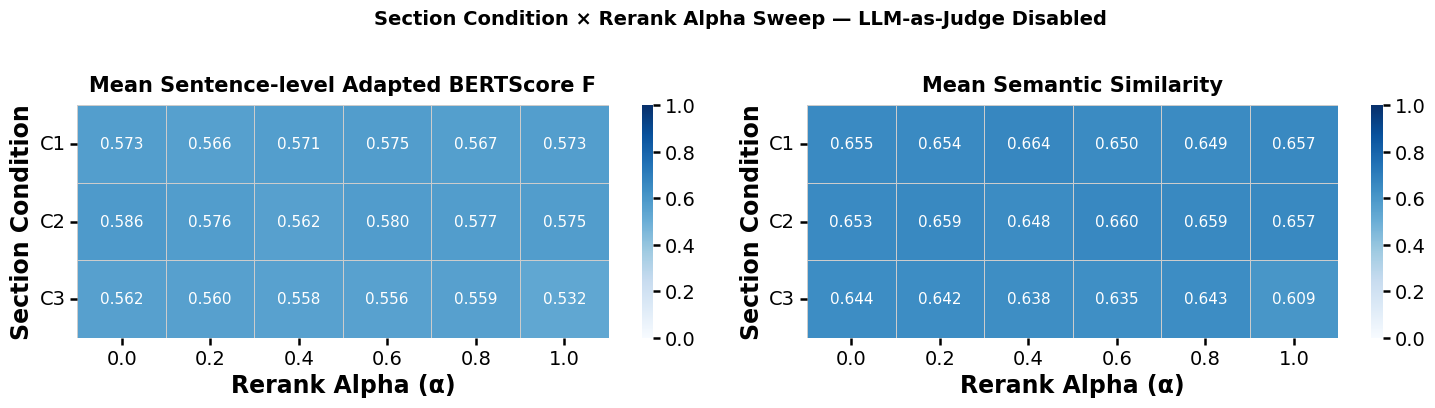

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/section_alpha_heatmap.{pdf,jpg}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for ax, pivot, title in zip(
    axes,
    [df_pivot_F,  df_pivot_SS],
    ['Mean Sentence-level Adapted BERTScore F', 'Mean Semantic Similarity'],
):
    sns.heatmap(
        pivot.astype(float), annot=True, fmt='.3f',
        cmap='Blues', vmin=0.0, vmax=1.0,
        linewidths=0.5, linecolor='#CCCCCC',
        annot_kws={'size': 11}, ax=ax,
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel('Rerank Alpha (α)')
    ax.set_ylabel('Section Condition')
    ax.tick_params(axis='y', rotation=0)

fig.suptitle(
    'Section Condition × Rerank Alpha Sweep — LLM-as-Judge Disabled',
    fontsize=14, fontweight='bold', y=1.02,
)
plt.tight_layout()

for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
    fig.savefig(OUTPUT_DIR / f'section_alpha_heatmap.{ext}',
                dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
plt.show()
print(f'Saved → {OUTPUT_DIR}/section_alpha_heatmap.{{pdf,jpg}}')

## Cell 8 — Bar Chart: BERTScore F & Semantic Similarity vs Rerank Alpha

Grouped bar chart with alpha on the x-axis, one bar group per alpha value, and three bars per group (one per section condition).

**Enhancements over a plain bar chart:**

| Feature | Description |
|---------|-------------|
| **Error bars** | ±1 SD across the 30 positive-control questions for each (condition, alpha) cell |
| **Grand mean line** | Dashed black line — mean of the three condition means at each alpha |
| **Grand mean band** | Shaded ±1 SD region around the grand mean, showing spread across conditions |
| **Significance brackets** | Paired Wilcoxon signed-rank test (same 30 questions per pair): C1 vs C3 and C2 vs C3 at each alpha; only significant comparisons are annotated (`*p<0.05`, `**p<0.01`, `***p<0.001`); `ns` brackets omitted for clarity |

**Pairs tested:** C1 (Abstract + Introduction) vs C3 (Evidence-only) and C2 (Full Corpus) vs C3 — comparing each non-default condition against the current production default.

**Colour palette:** colour-blind-safe (Okabe–Ito derived) — blue / orange / reddish-purple, no red+green pairing.

**Output files:** `section_alpha_barchart_bertscore_f1.pdf/.jpg` and `section_alpha_barchart_ss.pdf/.jpg` (plus separate `_legend` files) in `analysis/output/ScientificReportRevisionV1/section_condition/`.

Loaded 540 scored rows from disk -> bertscores_section_alpha_sweep.csv  (n=30 questions)


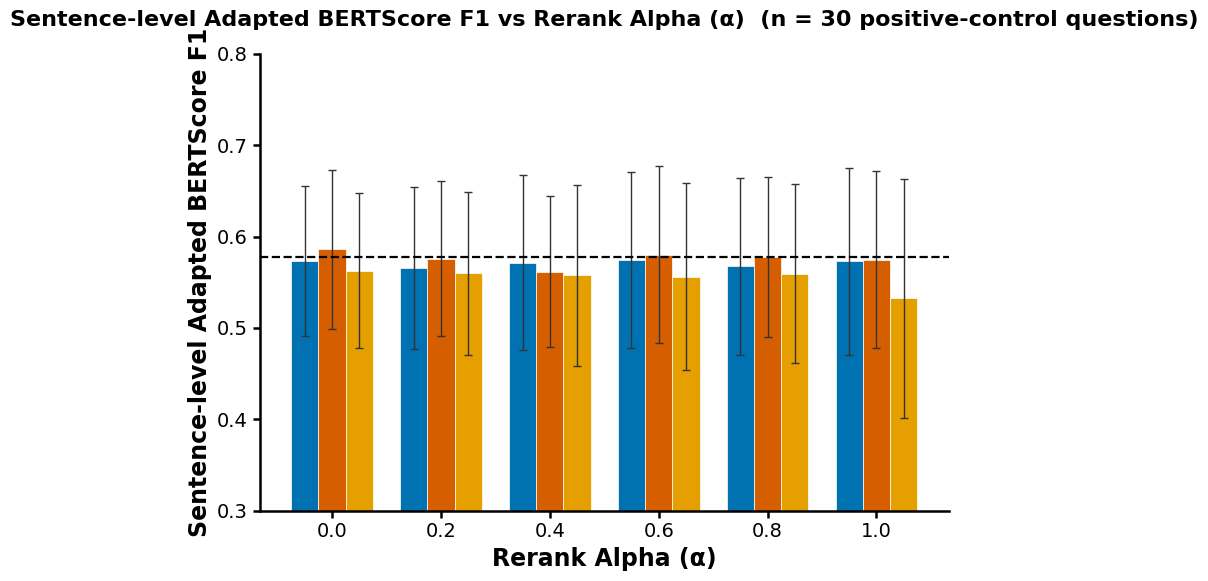

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/section_alpha_barchart_bertscore_f1.{pdf,jpg}
Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/section_alpha_barchart_bertscore_f1_legend.{pdf,jpg}


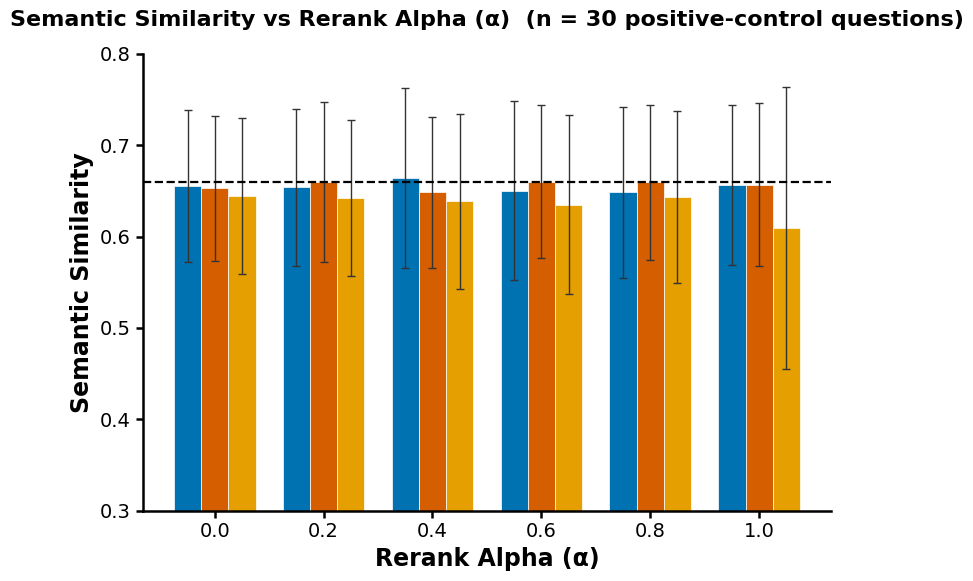

Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/section_alpha_barchart_ss.{pdf,jpg}
Saved → /path/to/project/T21_research_assistant_v7/analysis/output/ScientificReportRevisionV1/section_condition/section_alpha_barchart_ss_legend.{pdf,jpg}


In [9]:
from scipy import stats as sp_stats

# Load scores FROM DISK so this cell runs standalone after a kernel restart.
scores_csv = OUTPUT_DIR / 'bertscores_section_alpha_sweep.csv'
assert scores_csv.exists(), f'{scores_csv} not found - run Cell 5 first.'
df_scores = pd.read_csv(scores_csv)
n_q_this_run = int(df_scores['q_idx'].nunique())
print(f'Loaded {len(df_scores)} scored rows from disk -> {scores_csv.name}  (n={n_q_this_run} questions)')

# Colour-blind-safe palette (Okabe–Ito derived); avoids pairing red with green
# per reviewer feedback (red/green carries a "bad/good" connotation and is
# indistinguishable to common forms of color vision deficiency).
_colors   = ['#0072B2', '#D55E00', '#E69F00']   # matches six-method palette: T21 RAG blue, Nemotron vermillion, GPT-5.4 orange
cond_list = list(CONDITIONS.keys())

n_alpha   = len(ALPHA_VALUES)
n_cond    = len(cond_list)
bar_width = 0.25
x         = np.arange(n_alpha)
offsets   = [(i - n_cond / 2 + 0.5) * bar_width for i in range(n_cond)]


def _sig_label(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return None


def _bracket(ax, x1, x2, y, h, label, lw=0.8, fs=10):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=lw, c='#444')
    ax.text((x1 + x2) / 2, y + h + 0.003, label,
            ha='center', va='bottom', fontsize=fs, color='#444')


for metric, ylabel, fname_stem in [
    ('F',  'Sentence-level Adapted BERTScore F1', 'section_alpha_barchart_bertscore_f1'),
    ('SS', 'Semantic Similarity',                 'section_alpha_barchart_ss'),
]:
    fig, ax = plt.subplots(figsize=(8, 6))

    # ── bars + SD error bars ──────────────────────────────────────────────────
    top_with_err = {}
    all_means    = {}
    bar_handles  = []
    bar_labels   = []


    for ci, (cname, color) in enumerate(zip(cond_list, _colors)):
        sub   = df_scores[df_scores['condition'] == cname]
        grp   = sub.groupby('alpha')[metric]
        means = grp.mean()
        sds   = grp.std(ddof=1)
        vals  = [means[a] for a in ALPHA_VALUES]
        errs  = [sds[a]   for a in ALPHA_VALUES]
        label = cname.split(':', 1)[1].strip()
        bars = ax.bar(x + offsets[ci], vals, width=bar_width, color=color,
                      edgecolor='white', linewidth=0.5,
                      yerr=errs, error_kw=dict(elinewidth=1.0, capsize=3, ecolor='#333'))
        bar_handles.append(bars)
        bar_labels.append(label)
        for ai, a in enumerate(ALPHA_VALUES):
            top_with_err[(ci, ai)] = vals[ai] + errs[ai]
            all_means[(ci, ai)]    = vals[ai]

    # ── average-max horizontal dashed line ────────────────────────────────────
    max_per_alpha = [
        max(all_means[(ci, ai)] for ci in range(n_cond))
        for ai in range(n_alpha)
    ]
    avg_max = np.mean(max_per_alpha)
    line_h, = ax.plot([], [], color='black', lw=1.6, ls='--')   # legend proxy
    ax.axhline(avg_max, color='black', lw=1.6, ls='--', zorder=5)

    # ── significance brackets: C1 vs C3, C2 vs C3 ────────────────────────────
    pairs = [(0, 2), (1, 2)]
    _max_anno_y = 0.0
    bh    = 0.022
    gap   = 0.032

    for ai, a in enumerate(ALPHA_VALUES):
        base_y = max(top_with_err[(ci, ai)] for ci in range(n_cond)) + 0.018
        level  = 0
        for (ci, cj) in pairs:
            v_i = df_scores[
                (df_scores['condition'] == cond_list[ci]) & (df_scores['alpha'] == a)
            ][metric].values
            v_j = df_scores[
                (df_scores['condition'] == cond_list[cj]) & (df_scores['alpha'] == a)
            ][metric].values
            try:
                _, p = sp_stats.wilcoxon(v_i, v_j)
            except ValueError:
                p = 1.0
            lbl = _sig_label(p)
            if lbl:
                y0 = base_y + level * (bh + gap)
                _bracket(ax,
                         x[ai] + offsets[ci],
                         x[ai] + offsets[cj],
                         y0, bh, lbl)
                _max_anno_y = max(_max_anno_y, y0 + bh + 0.020)
                level += 1

    ax.set_xlabel('Rerank Alpha (α)', fontsize=17, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=17, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([str(a) for a in ALPHA_VALUES], fontsize=14)
    ax.tick_params(axis='y', labelsize=14, width=1.8)
    # headroom: keep the 0.3-0.8 window, extending the top only when significance
    # bracket labels would otherwise collide with the title
    ax.set_ylim(0.3, max(0.8, _max_anno_y + 0.025))
    ax.set_title(f'{ylabel} vs Rerank Alpha (\u03b1)  (n = {n_q_this_run} positive-control questions)',
                 fontsize=16, fontweight='bold', pad=20)
    plt.tight_layout()

    for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
        fig.savefig(OUTPUT_DIR / f'{fname_stem}.{ext}',
                    dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
    plt.show()
    print(f'Saved → {OUTPUT_DIR}/{fname_stem}.{{pdf,jpg}}')

    # ── legend figure ─────────────────────────────────────────────────────────
    all_handles = bar_handles + [line_h]
    all_labels  = bar_labels  + [f'Avg max ({avg_max:.3f})']

    fig_leg = plt.figure(figsize=(4, 2.2))
    fig_leg.legend(all_handles, all_labels, title='Legend',
                   fontsize=12, title_fontsize=13,
                   loc='center', frameon=True, framealpha=0.95)
    fig_leg.tight_layout()
    for fmt, ext in [('pdf', 'pdf'), ('jpeg', 'jpg')]:
        fig_leg.savefig(OUTPUT_DIR / f'{fname_stem}_legend.{ext}',
                        dpi=SAVE_DPI, bbox_inches='tight', format=fmt)
    plt.close(fig_leg)
    print(f'Saved → {OUTPUT_DIR}/{fname_stem}_legend.{{pdf,jpg}}')
